# Разработка A/B-тестирования и анализ результатов

В данном проекте я выступаю продуктовым аналитиком в компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В нашем приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Вас, как аналитика, просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Для работы у нас есть три таблицы:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Что нужно сделать
Моя задача заключается в том, чтобы рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

<div style="background-color: #f0f0f0;"> Улучшение системы рекомендаций напрямую влияет на вовлеченность аудитории. Увеличение времени в приложении обеспечит рост доходов компании: за счет большего количества рекламных контактов и повышения ценности платной подписки для пользователей.
В рамках текущего анализа мы изучим количественные показатели и долю зарегистрированных пользователей, а также проанализируем распределение глубины просмотра (количество страниц за сессию) как ключевой индикатор вовлеченности.
Главной задачей проекта будет проведение тестирования нового алгоритма с целбю выявления положительного результата, и проверкой этого результата на статистическую значимость, чтобы понять насколько действенен новый алгоритм рекомендаций.
Ключевая цель проекта — оценка эффективности нового алгоритма рекомендаций. Нам необходимо не только зафиксировать положительную динамику метрик, но и подтвердить статистическую значимость полученных результатов, чтобы обосновать целесообразность внедрения алгоритма в промышленную эксплуатацию. </div>

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных
На первом этапе поработаем с историческими данными приложения:

In [ ]:
# Импортируем необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from math import ceil
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# Считываем и сохраняем csv файл в датафрейм sessions_histor и выводим первые пять строк
sessions_history = pd.read_csv('/datasets/sessions_project_history.csv')
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными

In [3]:
# Для каждого уникального пользователя `user_id` рассчитаем количество уникальных сессий 
# и выведем  все данные из таблицы для одного пользователя с наибольшим количеством сессий
user_max_count_session = sessions_history['user_id'].value_counts().idxmax()
user_max_count_session

'10E0DEFC1ABDBBE0'

In [4]:
# Выведем из таблицы sessions_history все данные по выбранному пользователю
sessions_history[sessions_history['user_id'] == user_max_count_session]

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируйте, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, вам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU, но для регистраций пользователей).

In [5]:
# Проверим типы данных в датафрейме sessions_history
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            435924 non-null  object
 1   session_id         435924 non-null  object
 2   session_date       435924 non-null  object
 3   session_start_ts   435924 non-null  object
 4   install_date       435924 non-null  object
 5   session_number     435924 non-null  int64 
 6   registration_flag  435924 non-null  int64 
 7   page_counter       435924 non-null  int64 
 8   region             435924 non-null  object
 9   device             435924 non-null  object
dtypes: int64(3), object(7)
memory usage: 33.3+ MB


In [6]:
# Преобразуем столбцы, содержащие даты, к типу данных datetime64
dates = ['session_date', 'session_start_ts','install_date']
for date in dates:
    sessions_history[date] = pd.to_datetime(sessions_history[date])

In [7]:
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   user_id            435924 non-null  object        
 1   session_id         435924 non-null  object        
 2   session_date       435924 non-null  datetime64[ns]
 3   session_start_ts   435924 non-null  datetime64[ns]
 4   install_date       435924 non-null  datetime64[ns]
 5   session_number     435924 non-null  int64         
 6   registration_flag  435924 non-null  int64         
 7   page_counter       435924 non-null  int64         
 8   region             435924 non-null  object        
 9   device             435924 non-null  object        
dtypes: datetime64[ns](3), int64(3), object(4)
memory usage: 33.3+ MB


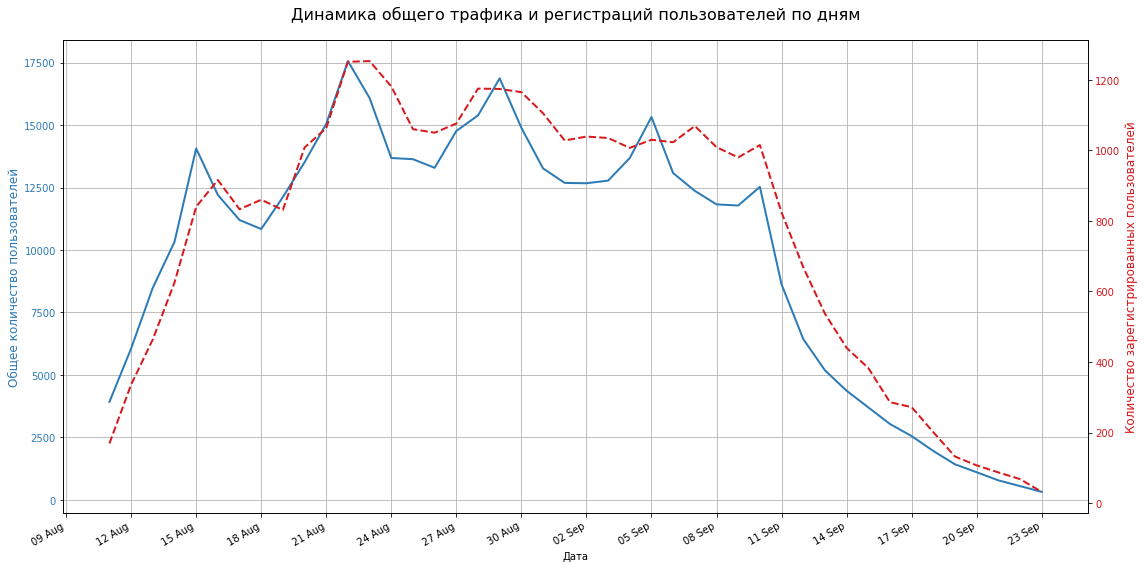

In [8]:
# Найдем общее количество пользователей в день
all_users = sessions_history.groupby('session_date').user_id.nunique()
# Найдем общее количество зарегистрированных пользователей в день
register_users = sessions_history[sessions_history['registration_flag']==1].groupby('session_date').user_id.nunique()

fig, ax1 = plt.subplots(figsize=(16, 8))

# 1. Строим график общего количества пользователей 
ax1.plot(all_users.index, all_users.values, color='#2c7bb6', label='Всего пользователей', linewidth=2)
ax1.set_xlabel('Дата')
ax1.set_ylabel('Общее количество пользователей', color='#2c7bb6', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#2c7bb6')

# 2. Создаем вторую ось Y для регистраций
ax2 = ax1.twinx() 
ax2.plot(register_users.index, register_users.values, color='#d7191c', label='Зарегистрированные', linewidth=2, linestyle='--')
ax2.set_ylabel('Количество зарегистрированных пользователей', color='#d7191c', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#d7191c')

ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gcf().autofmt_xdate() 

plt.title('Динамика общего трафика и регистраций пользователей по дням', fontsize=16, pad=20)
ax1.grid(True)

plt.tight_layout()
plt.show()

<div style="background-color: #f0f0f0;">Для корректного сравнения несопоставимых по масштабу величин мы применили две оси Y. Динамика общего количества пользователей и зарегистрированных пользователей практически идентична.
Тем не менее, начиная с 11 сентября, на графиках виден аномально резкий спад. Такое единообразное падение указывает на системную проблему: возможно, произошел технический сбой или была прекращена маркетинговая поддержка приложения. </div>

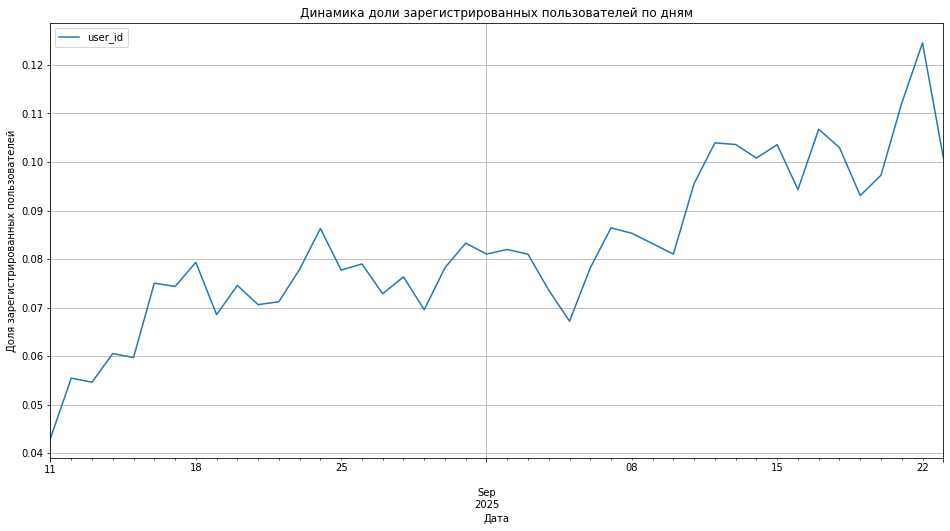

In [9]:
plt.figure(figsize=(16, 8))


(register_users/all_users).plot()
plt.xlabel('Дата')
plt.ylabel('Доля зарегистрированных пользователей')
plt.legend()
plt.grid(True)
plt.title('Динамика доли зарегистрированных пользователей по дням')
plt.show()

<div style="background-color: #f0f0f0;">В пиковые периоды средняя доля зарегистрированных пользователей составляла около 8%. В сентябре, на фоне резкого сокращения общего трафика, наблюдается рост относительного показателя регистраций.Это значит, что случайные посетители ушли, а в приложении остались лояльные пользователи, которые остались в приложении.</div>

#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

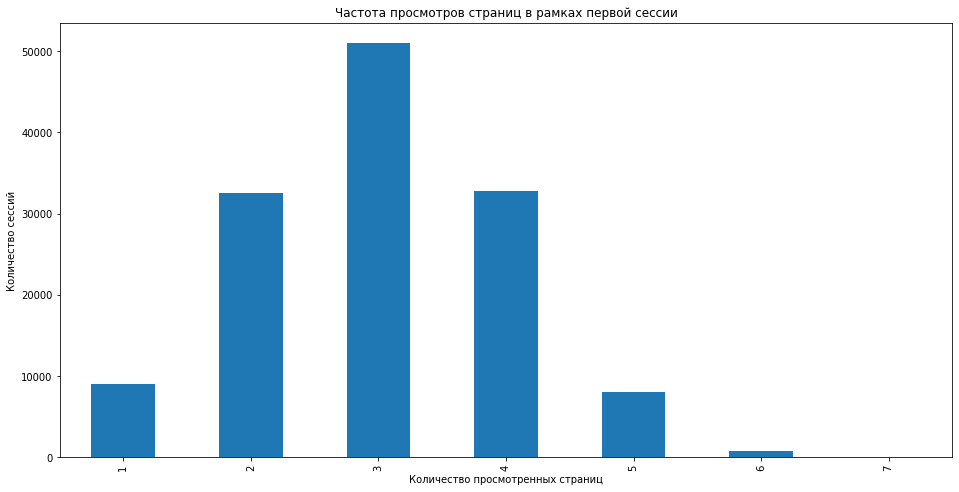

In [10]:
# Проанализируем число просмотренных страниц во время первых сессий пользователей
count_pages_first_session = sessions_history[sessions_history['session_number'] == 1]['page_counter'].value_counts()
# Построим диаграмму
plt.figure(figsize=(16, 8))
count_pages_first_session.sort_index().plot(kind= 'bar')
plt.xlabel('Количество просмотренных страниц')
plt.ylabel('Количество сессий')
plt.title('Частота просмотров страниц в рамках первой сессии')
plt.show()

<div style="background-color: #f0f0f0;">Анализ распределения просмотренных страниц показал, что наиболее характерным поведением является просмотр 3 страниц за сессию. Основная масса пользователей ограничивается 2–4 просмотрами. Чтобы новый алгоритм работал на реальное вовлечение, было решено установить планку "успеха" на уровне 4 страниц.</div>

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

In [11]:
# Создадим дополнительный столбец good_session. В него войдёт значение 1, если за одну сессию было просмотрено 4 и более страниц,
# и значение 0, если было просмотрено меньше.
def count_page(row):
    if row['page_counter'] >= 4:
        return 1
    else:
        return 0

sessions_history['good_session'] = sessions_history.apply(count_page, axis = 1)
sessions_history.head(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,good_session
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone,0
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android,1
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC,1
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android,1
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android,0


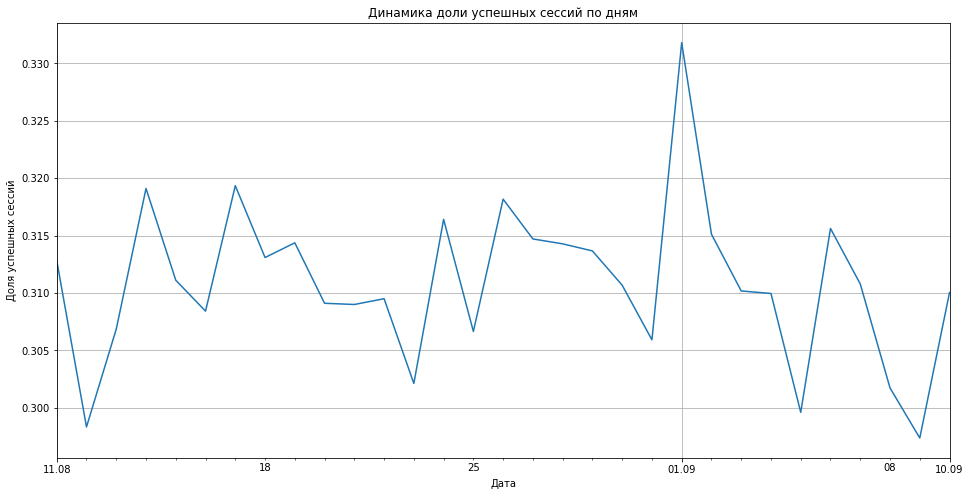

In [12]:
# Создадим датафрейм с долями успешных сессий по дням
perc_suc_sess = sessions_history[sessions_history['session_number']==1].groupby('session_date').agg({'good_session':'mean'})
# Построим график
ax = perc_suc_sess.plot(figsize=(16, 8), legend = False)
date_form = mdates.DateFormatter("%d.%m")
ax.xaxis.set_major_formatter(date_form)
plt.grid(True)
plt.xlabel('Дата')
plt.ylabel('Доля успешных сессий')
plt.title('Динамика доли успешных сессий по дням')
plt.show()

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки
Рассчитаем необходимое для нашего эксперимента количество пользователей со следующими параметрами:

- Уровень значимости — 0.05.

- Вероятность ошибки второго рода — 0.2.

- Мощность теста.

- Минимальный детектируемый эффект, или MDE, — 3%

In [13]:
# Зададим параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03 * p  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)


# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### 2.2. Расчёт длительности A/B-теста

Используя данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения, рассчитаем длительность теста.

In [14]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = round(all_users.mean())

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(sample_size*2/avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907 пользователей в день составит 9 дней


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются.

In [15]:
# Сохраняем данные в датафрейс и выводим первые 5 строк
sessions_test_part = pd.read_csv('/datasets/sessions_project_test_part.csv')
sessions_test_part.head(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


In [16]:
# Рассчитываеи количество уникальных пользователей в каждой группе
count_group = sessions_test_part.groupby('test_group')['user_id'].nunique()
count_group

test_group
A    1477
B    1466
Name: user_id, dtype: int64

In [17]:
# Рассчитаем процентную разницу в количестве пользователей в группах A и B.
p = 100 * (abs(count_group['A'] - count_group['B']))/count_group['A']
round(p,2)

0.74

Процентная разница составляет менее 1 %, что говорит о том, что пользователи распределены между группами равномерно.

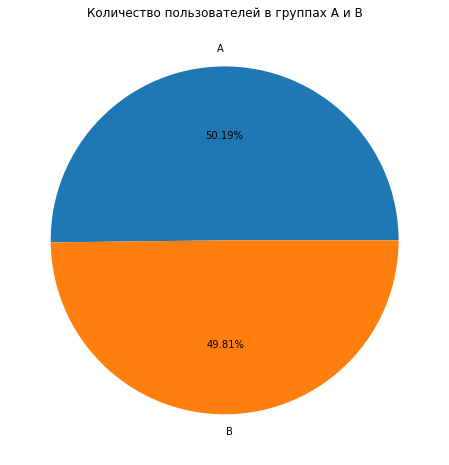

In [18]:
# Построим график распределения количества пользователей между группами
plt.figure(figsize=(16, 8))
count_group.plot(kind= 'pie', 
                autopct='%1.2f%%')

plt.title('Количество пользователей в группах A и B')
plt.ylabel('')
plt.show()

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

In [19]:
# Разделим датафрейм на два датафрейма для групп A и B
group_a = sessions_test_part[sessions_test_part['test_group']== 'A']
group_b = sessions_test_part[sessions_test_part['test_group']== 'B']

In [20]:
# Рассчитаем количесвто пользователей, встречающихся в обеих группах
double_users = set(group_a['user_id'])&set(group_b['user_id'])
len(double_users)

0

Множество пользователей в контрольной и тестовой группах не пересекаются. Условие независимости выборок соблюдено.

#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Для корректного анализа распределения исключим повторные записи о сессиях, оставив по одному уникальному пользователю.

In [21]:
# Определим количество различных устройств для уникальных пользователей
device_a = group_a.drop_duplicates(['user_id', 'device'])['device'].value_counts()
device_b = group_b.drop_duplicates(['user_id', 'device'])['device'].value_counts()

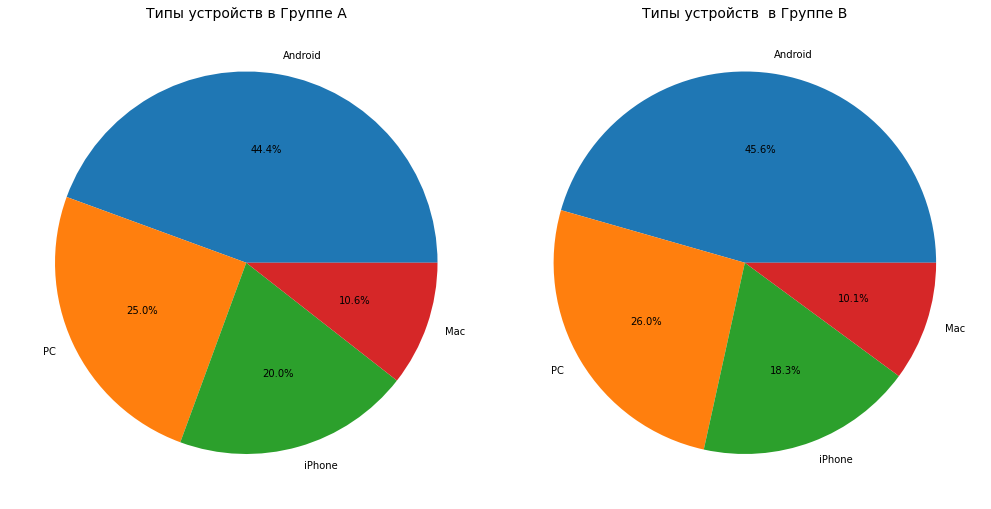

In [22]:
# Построим две диаграммы доли каждого типа устройства для пользователей из групп A и В
fig, axes = plt.subplots(1, 2, figsize=(14, 7))


axes[0].pie(device_a, 
    labels = device_a.index,
    autopct='%1.1f%%'
)
axes[0].set_title('Типы устройств в Группе A', fontsize=14)

axes[1].pie(
    device_b, 
    labels = device_b.index,
    autopct='%1.1f%%'
)
axes[1].set_title('Типы устройств  в Группе B', fontsize=14)

plt.tight_layout()
plt.show()

Распределение пользователей по используемым устройствам в группах A и B равномерно. Статистически значимых перекосов не обнаружено (вариация долей в пределах 2%).

#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедитесь, что пользователи равномерно распределены по регионам.

In [23]:
region_a = pd.DataFrame(group_a.drop_duplicates(['user_id', 'region'])['region'].value_counts(normalize = True))
region_b = pd.DataFrame(group_b.drop_duplicates(['user_id', 'region'])['region'].value_counts(normalize = True))
regions = region_a.join(region_b, how = 'inner', lsuffix = '_a', rsuffix = '_b')
regions

,region_a,region_b
CIS,0.436019,0.439973
MENA,0.412322,0.412005
EU,0.151659,0.148022


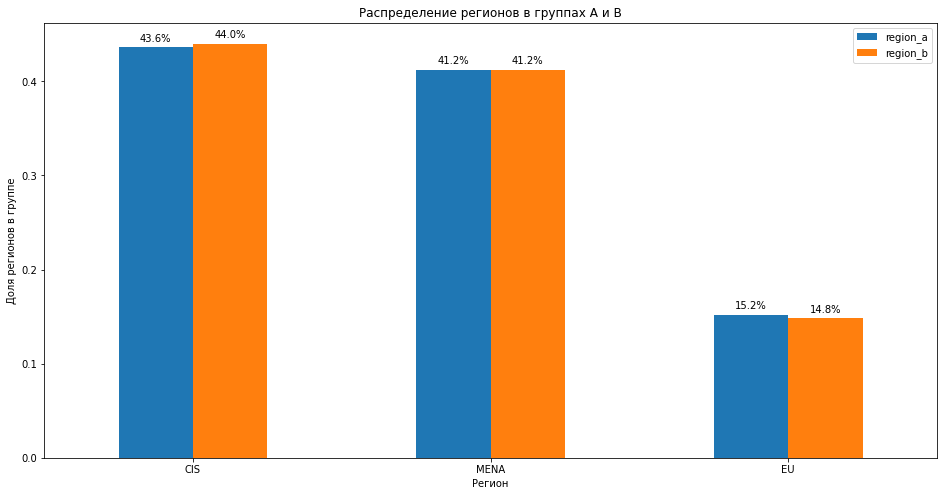

In [24]:
# Построим две диаграммы доли каждогорегиона для пользователей из групп A и В
ax = regions.plot(kind = 'bar', figsize = (16,8))
for p in ax.patches:
        ax.annotate(f'{p.get_height():.1%}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 9), 
                textcoords='offset points',
                fontsize=10)
plt.xlabel('Регион')
plt.ylabel('Доля регионов в группе')
plt.xticks(rotation=0)
plt.title('Распределение регионов в группах A и B')
plt.show()

Распределение по регионам так же выглядит равномерным. Вариация долей менее 1%.

#### 3.5. Вывод после проверки A/B-теста

Мониторинг первого дня теста показал корректное разделение трафика: группы А и В сбалансированы по количеству пользователей и не имеют пересечений. Сходство распределений по географии и техническим платформам подтверждает репрезентативность данных и готовность эксперимента к дальнейшему анализу целевых метрик

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у нас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

In [25]:
# Выгрузим датасет с результатами A/B-теста
sessions_test = pd.read_csv('/datasets/sessions_project_test.csv')
sessions_test.head(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B


In [26]:
# Создадим дополнительный столбец good_session используя функция count_page, объявленную ранее в проекте
sessions_test['good_session'] = sessions_test.apply(count_page, axis = 1)
sessions_test.head(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик

Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Напомним изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

Новый алгоритм подбора интересного контента в приложении теоретически может привести к увеличению числа просмотренных страниц. Однако среднее количество просмотренных страниц будет плохой целевой метрикой, т.к. среднее очень подвержено выбросам, и случайный пользователь, который просмотрит большое количество страниц, сильно повлияет на метрику всей группы. Поэтому в качестве **ключевой метрики** лучше использовать **долю первых успешных сессий**.

В качестве **прокси-метрики** целесообразно использовать **длительность сессии**, так как рост времени нахождения в приложении напрямую коррелирует с объемом потребляемого контента. Однако эта метрика требует осторожной интерпретации: её увеличение может быть вызвано не вовлеченностью, а техническими задержками или сложностями в навигации.

Роль **барьерной метрики** в эксперименте могла быть отведенна **времени загрузки контента**. Она позволяет своевременно идентифицировать технические сбои и выступает ключевым критерием остановки теста. Если на фоне роста длительности сессий количество просмотренных страниц стагнирует или снижается, это сигнализирует о чрезмерной вычислительной сложности нового алгоритма. Рост задержек при выдаче рекомендаций критически повышает риск оттока пользователей, что делает внедрение такого алгоритма недопустимым.

Перейдем к формулировке гипотез.

**Нулевая гипотеза H_0**: Новый алгоритм рекомендаций не влияет на вовлеченность пользователей.
**H_0 : p_a = p_b**

**Альтернативная гипотеза H_1** Новый алгоритм рекомендаций увеличивает вовлеченность пользователей.
**H_1 : p_a < p_b**

#### 4.3. Сравнение доли успешных сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

In [27]:
# Рассчитаем долю успешных первых сессий для выборок A и B, а также разницу в этом показателе
gs_group_a = sessions_test[(sessions_test['test_group'] == 'A')&(sessions_test['session_number'] == 1)]['good_session'].mean()
gs_group_b = sessions_test[(sessions_test['test_group'] == 'B')&(sessions_test['session_number'] == 1)]['good_session'].mean()
print(f'Доля успешных сессий для группы A равна {round(gs_group_a,3)}')
print(f'Доля успешных сессий для группы B равна {round(gs_group_b,3)}')
print(f'Разница в показателях {round(gs_group_b - gs_group_a,3)}')

Доля успешных сессий для группы A равна 0.316
Доля успешных сессий для группы B равна 0.315
Разница в показателях -0.001


Доли успешных сессий в обеих группах практически идентичны. Зафиксировано символическое снижение показателя в тестовой группе на 0.1 процентный пункт. При такой ничтожной разнице результат с высокой вероятностью является статистически незначащим, однако чтобы точно убедиться в этом проведем статистический тест.

#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге мы убедились, что количество успешных сессий в тестовой выборке примерно на 0.1% выше, чем в контрольной, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.
Используем статистический тест и  рассчитаем, является ли изменение в метрике доли успешных сессий статистически значимым.

Так как в качестве целевой метрики мы выбрали долевую метрику, для статистического теста лучше всего подойдет Z-тест пропорций.

In [28]:
# найдем размер группы А
n_a = sessions_test[(sessions_test['test_group'] == 'A')&(sessions_test['session_number'] == 1)].shape[0]
# найдем размер группы А
n_b = sessions_test[(sessions_test['test_group'] == 'B')&(sessions_test['session_number'] == 1)].shape[0]

# Посчитаем количество успехов в группе A
m_a = sessions_test[(sessions_test['test_group'] == 'A')&(sessions_test['session_number'] == 1)&(sessions_test['good_session'] == 1)].shape[0]
# Посчитаем количество успехов в группе B
m_b = sessions_test[(sessions_test['test_group'] == 'B')&(sessions_test['session_number'] == 1)&(sessions_test['good_session'] == 1)].shape[0]

# Рассчитаем доли успехов для каждой группы
p_a, p_b = m_a/n_a, m_b/n_a

# Проверим предпосылку о достаточном количестве данных
if (p_a*n_a>10)and((1-p_a)*n_a>10)and(p_b*n_b>10)and((1-p_b)*n_b>10):
    print('Предпосылка о достаточном количестве данных выполняется!')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется!')

alpha = 0.05
stat_ztest, p_value_ztest = proportions_ztest([m_a, m_b],
                                              [n_a, n_b],
                                              alternative='smaller')
# Выведем полученное p-значение
print(f'pvalue={p_value_ztest}')
if p_value_ztest > alpha:
    print('Нулевая гипотеза находит подтверждение!')
else:
    print('Нулевая гипотеза не находит подтверждения!')


Предпосылка о достаточном количестве данных выполняется!
pvalue=0.5783523649187868
Нулевая гипотеза находит подтверждение!


Полученное значение p-value намного выше уровня значимости, что не позволяет нам отвергнуть нулевую теорию. Это говорит о том, что новый алгоритм работает практически идентично старому.

#### 4.5. Вывод по результатам A/B-эксперимента

Мы разработали новый алгоритм для видеоленты и решили проверить, станет ли пользователям интереснее смотреть контент. «Успешной» считали сессию, где человек посмотрел 4 и более видео. Предварительный расчет показал, что для надежного результата нам нужно по 41 040 человек в каждой группе, а сам тест должен длиться 9 дней.
Через три дня после старта мы проверили, как идет разделение трафика. Группы А и В оказались равны: в них нет пересечений, а пользователи из разных регионов и с разными устройствами распределены поровну. Это значит, что выборка чистая и результатам можно верить.
Нашей главной целью было увеличить долю успешных первых сессий. Мы сравнивали старый алгоритм (группа А) и новый (группа В). Доли успешных сессий в группах равны в пределах статистической погрешности.
Статистический тест не дал оснований отклонить нулевую гипотезу (значение p-value = 0.578). Это говорит о тос, что новый алгоритм не отличается от текущего.
Рекомендуем оставить текущую версию алгоритма. Команде разработки следует проанализировать причины отсутствия роста и подготовить новую гипотезу для следующей итерации теста.